In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

# import time
# import copy
import gc
import math

import matplotlib.pyplot as plt
import seaborn as sns
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from utils import get_opt, get_loaders, eval_ppl

In [2]:
DEV = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# Load

## Model

In [3]:
# model_name = "HuggingFaceTB/SmolLM2-135M"
model_name = "HuggingFaceTB/SmolLM2-1.7B"

model = get_opt(model_name)
model.eval()
model.to(DEV)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 2048)
    (layers): ModuleList(
      (0-23): 24 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (v_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,), eps=1e-05)
    (rotary_emb)

## Datasets

In [4]:
# n_samples = 32
n_samples = 128
# n_samples = 1

dataloader, testloader = get_loaders(
    "c4", nsamples=n_samples, seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (8597 > 8192). Running this sequence through the model will result in indexing errors


In [5]:
wiki_dataloader, wiki_testloader = get_loaders(
    'wikitext2', seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (2565857 > 8192). Running this sequence through the model will result in indexing errors


ts torch.Size([1, 2565857])


In [6]:
base_ppl = eval_ppl(model, testloader, device=DEV)
base_loss = float(np.log(base_ppl))
base_ppl, base_loss

(11.781546592712402, 2.4665344593096408)

# Architecture

In [7]:
class TokenGate(nn.Module):
    def __init__(self, d_model, noise_scale=0.0, tau=1.0):
        super().__init__()
        self.proj = nn.Linear(d_model, 1, dtype=torch.bfloat16)
        self.noise_scale = noise_scale
        self.tau = tau

    def forward(self, h):
        logits = self.proj(h)              # [B, T, 1]
        
        u = torch.rand_like(logits).clamp(1e-6, 1-1e-6)
        noise = torch.log(u) - torch.log(1-u)        # logistic noise

        if self.training and self.noise_scale > 0:
            # logits = logits + self.noise_scale * torch.randn_like(logits)
            logits = logits + self.noise_scale * noise

        gate = torch.sigmoid(logits / self.tau)
        return gate                        # [B, T, 1]


In [8]:
class GatedMLP(nn.Module):
    def __init__(self, mlp: nn.Module, d_model: int, gate_store: list,  noise_scale=0.0, tau=1.0):
        super().__init__()
        self.mlp = mlp
        self.gate = TokenGate(d_model, noise_scale=noise_scale, tau=tau)
        self.gate_store = gate_store      # to collect gates for loss

    def forward(self, h):
        g = self.gate(h)                  # [B, T, 1]
        self.gate_store.append(g)

        if self.training:            
            return g * self.mlp(h)        # Standard continuous gating
        
        # --- Inference / Eval Mode Logic ---
        g_binary = (g > 0.5).to(h.dtype)
        g_flat = g_binary.view(-1)        # [B*T]
        h_flat = h.view(-1, h.size(-1))   # [B*T, D]
        active_indices = torch.where(g_flat > 0.5)[0]

        out_flat = torch.zeros_like(h_flat)
        if active_indices.numel() > 0:
            # only compute MLP for active tokens
            h_active = h_flat[active_indices]
            out_active = self.mlp(h_active)
            
            out_flat[active_indices] = out_active

        return out_flat.view(h.shape)

In [9]:
def freeze_all_but_gates(model):
    for p in model.parameters():
        p.requires_grad = False
    for layer in model.model.layers:
        for p in layer.mlp.gate.parameters():   # TokenGate parameters
            p.requires_grad = True

def get_gate_params(model):
    params = []
    for layer in model.model.layers:
        params += list(layer.mlp.gate.parameters())
    return params

def set_init_gate_weights(model, init_keep=0.7):
    init_logit = math.log(init_keep / (1 - init_keep))

    for layer in model.model.layers:
        # initialization
        gate = layer.mlp.gate.proj
        # gate.weight.data.zero_()
        gate.bias.data.fill_(init_logit)
        gate.weight.data.normal_(0.0, 1e-1)
        # gate.bias.data.zero_()
        

In [47]:
def gated_loss(lm_loss, gate_store,
               target_skip=0.3, lambda_ratio=1.0, lambda_bin=1.0):
    """
    lm_loss: scalar tensor
    gate_store: list of tensors [B, T, 1] (keep gates)
    """
    loss_gap = (lm_loss - base_loss)**2
    
    # concatenate all gates -> [B*T*L]
    g = torch.cat([gi.reshape(-1) for gi in gate_store], dim=0)
    skip_ratio = (1.0 - g).mean()

    # ratio loss (keep skip near target)
    ratio_loss = (skip_ratio - target_skip) ** 2

    # binarization loss (push gates to 0 or 1)
    bin_loss = (g * (1.0 - g)).mean()

    # total_loss = lm_loss + lambda_ratio * ratio_loss + lambda_bin * bin_loss
    total_loss = loss_gap + lambda_ratio * ratio_loss + lambda_bin * bin_loss

    return total_loss, {
        "skip_ratio": skip_ratio.detach(),
        "ratio_loss": ratio_loss.detach(),
        "bin_loss": bin_loss.detach(),
    }

In [11]:
def add_gates(model, gate_store, noise_scale=0.0, tau=1.0):
    for layer in model.model.layers:
        d_model = layer.mlp.gate_proj.in_features
        layer.mlp = GatedMLP(layer.mlp, d_model, gate_store, noise_scale=noise_scale, tau=tau)

def set_noise(model, noise_scale=0.0):
    for layer in model.model.layers:
        layer.mlp.gate.noise_scale = noise_scale

def set_tau(model, tau=1.0):
    for layer in model.model.layers:
        layer.mlp.gate.tau = tau

In [12]:
def train_gates(model, dataloader, gate_store, stats, device="cuda",
                epochs=1, lr=1e-3,
                target_skip=0.30, lambda_ratio=1.0, lambda_bin=1.0,
                grad_accum_steps=1, max_grad_norm=1.0, 
                verbose=False, eval_val_ppl=True, log_every=50):
    
    T = epochs * len(dataloader)     # total steps = 256

    # optimizer on gate params only
    gate_params = get_gate_params(model)
    optimizer = torch.optim.AdamW(gate_params, lr=lr)
    # scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.999)
    scheduler = torch.optim.lr_scheduler.LinearLR(
        optimizer,
        start_factor=1.0,
        end_factor=0.01,
        total_iters=T,
    )
    # scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    #     optimizer,
    #     T_max=T,
    #     eta_min=1e-4
    # )
    
    global_step = 0
    for epoch in range(epochs):
        for step, batch in enumerate(dataloader):
            global_step += 1
            gate_store.clear()

            input_ids, labels = batch
            batch = {"input_ids": input_ids.to(device), "labels": labels.to(device)}

            ##
            t = global_step / (T - 1)          # goes 0 -> 1
            
            tau = max(0.4, 1.0 - (1.0 - 0.4) * (t / 0.5))
            sigma = 0.5 * max(0.0, 1.0 - t/0.7)     # 0.5 -> 0 by 70% of training

            set_tau(model, tau)
            set_noise(model, sigma)
                        
            ##
            
            outputs = model(**batch)
            
            lm_loss = outputs.loss
            loss, loss_info = gated_loss(lm_loss, gate_store, lambda_ratio=lambda_ratio, lambda_bin=lambda_bin, target_skip=target_skip)
            loss = loss / grad_accum_steps
            loss.backward()

            if global_step % grad_accum_steps == 0:
                if max_grad_norm is not None:
                    torch.nn.utils.clip_grad_norm_(gate_params, max_grad_norm)
                optimizer.step()
                optimizer.zero_grad(set_to_none=True)
                scheduler.step()

            # logging
            if global_step % log_every == 0:
                with torch.no_grad():
                    ppl = torch.exp(lm_loss.detach()).item()
                    if eval_val_ppl:
                        model.eval()
                        val_ppl = eval_ppl(model, testloader, device=DEV)
                        model.train()
                    else: 
                        val_ppl = 0
                    lr = optimizer.param_groups[0]["lr"]
                    total_loss = lm_loss + lambda_ratio*loss_info['ratio_loss'] + lambda_bin*loss_info['bin_loss']
                    if verbose:
                        print(
                            f"epoch {epoch} step {global_step:3} lr {lr:.1e} tau {tau:.2f} sigma {sigma:.2f} | "
                            f"lm_loss={lm_loss.item():.2f} | "
                            f"ppl={ppl:6.2f} | val_ppl={val_ppl:6.2f} | "
                            f"skip_ratio={loss_info['skip_ratio'].item():.2f} | "
                            # f"ratio_loss={(lambda_ratio*loss_info['ratio_loss']).item():.2f} | "
                            f"bin_loss={(lambda_bin*loss_info['bin_loss']).item():.2f} | "
                            f"total_loss={total_loss.item():.2f}"
                        )
                    stats['ppl'].append(ppl)
                    stats['val_ppl'].append(val_ppl)
                    stats['skip_ratio'].append(loss_info['skip_ratio'].item())
                    stats['ratio_loss'].append((lambda_ratio*loss_info['ratio_loss']).item())
                    stats['bin_loss'].append((lambda_bin*loss_info['bin_loss']).item())
                    stats['total_loss'].append(total_loss.item())

    return model, stats

In [48]:
model = get_opt(model_name)
gate_store = []
add_gates(model, gate_store=gate_store)#, noise_scale=0.3, tau=0.3)
model.to(DEV)
model.train();

# Training

In [49]:
stats = {'ppl': [], 'val_ppl': [], 'skip_ratio': [], 'ratio_loss': [], 'bin_loss': [], 'total_loss': []}

set_init_gate_weights(model, init_keep=0.7)
freeze_all_but_gates(model)

model, stats = train_gates(
    model=model,
    dataloader=dataloader,
    gate_store=gate_store,
    stats=stats,
    device=DEV,
    epochs=3,
    lr=1e-2,
    target_skip=0.30,
    lambda_ratio=1e3,
    lambda_bin=10,
    grad_accum_steps=1,
    log_every=32,
    verbose=True
)
# model.eval();

epoch 0 step  32 lr 9.2e-03 tau 0.90 sigma 0.44 | lm_loss=10.36 | ppl=31512.30 | val_ppl= 30.80 | skip_ratio=0.33 | bin_loss=1.12 | total_loss=12.38
epoch 0 step  64 lr 8.3e-03 tau 0.80 sigma 0.38 | lm_loss=3.29 | ppl= 26.86 | val_ppl= 30.24 | skip_ratio=0.29 | bin_loss=1.14 | total_loss=4.51
epoch 0 step  96 lr 7.5e-03 tau 0.70 sigma 0.32 | lm_loss=0.46 | ppl=  1.58 | val_ppl= 27.60 | skip_ratio=0.32 | bin_loss=0.80 | total_loss=1.53
epoch 0 step 128 lr 6.7e-03 tau 0.60 sigma 0.26 | lm_loss=0.62 | ppl=  1.86 | val_ppl= 30.30 | skip_ratio=0.31 | bin_loss=0.69 | total_loss=1.52
epoch 1 step 160 lr 5.9e-03 tau 0.50 sigma 0.20 | lm_loss=2.99 | ppl= 19.80 | val_ppl= 36.02 | skip_ratio=0.32 | bin_loss=0.39 | total_loss=3.64
epoch 1 step 192 lr 5.0e-03 tau 0.40 sigma 0.14 | lm_loss=2.23 | ppl=  9.27 | val_ppl= 38.78 | skip_ratio=0.30 | bin_loss=0.37 | total_loss=2.61
epoch 1 step 224 lr 4.2e-03 tau 0.40 sigma 0.08 | lm_loss=0.49 | ppl=  1.63 | val_ppl= 40.20 | skip_ratio=0.30 | bin_loss=0.31

## Training stats

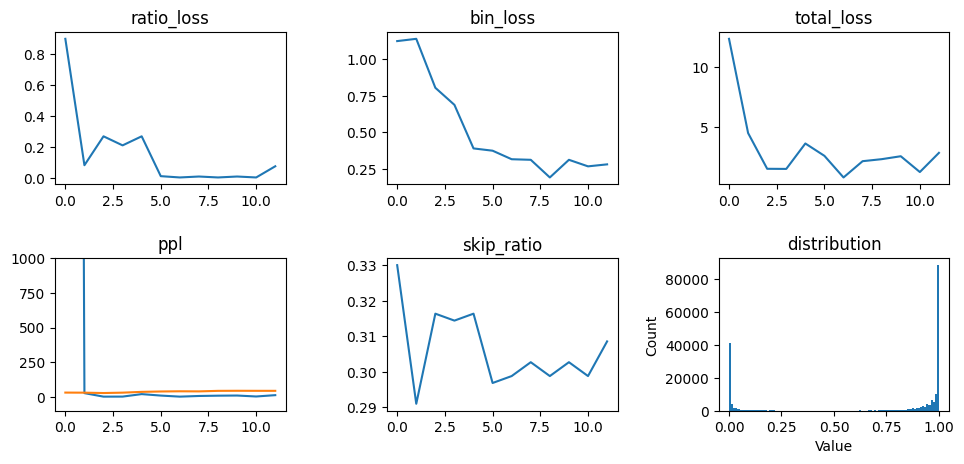

In [50]:
fig, ax = plt.subplots(2, 3, figsize=(10, 5))
for i, x in enumerate(['ratio_loss', 'bin_loss', 'total_loss', 'ppl', 'skip_ratio', 'distribution']):
    r, c = divmod(i, 3)
    if x == 'distribution':
        flat = torch.cat([t.reshape(-1) for t in gate_store[-24:]])
        values = flat.float().detach().cpu().numpy()
        ax[r, c].hist(values, bins=100)
        ax[r, c].set_xlabel("Value")
        ax[r, c].set_ylabel("Count")
        ax[r, c].set_title(x)
        continue
    ax[r, c].plot(stats[x])
    ax[r, c].set_title(x)
    if x == 'ppl': 
        ax[r, c].plot(stats['val_ppl'])
        if (max(stats['ppl']) > 1e2) or (max(stats['val_ppl']) > 1e2):
            ax[r, c].set_ylim((-1e2, 1e3))
fig.tight_layout(pad=2)

## Decision visualization

In [51]:
def visualize_gate_heatmap(gate_store):
    """
    gate_store: list of tensors [1, T, 1], one per layer
    """

    # Shape: [L, T]
    mat = torch.stack([g.squeeze() for g in gate_store], dim=0)
    mat = mat.detach().cpu().float().numpy()

    plt.figure(figsize=(12, 6))
    plt.imshow(mat, aspect="auto")
    plt.colorbar(label="Gate value")
    plt.xlabel("Token index")
    plt.ylabel("Layer index")
    plt.title("Gate heatmap (layers × tokens)")
    plt.show()


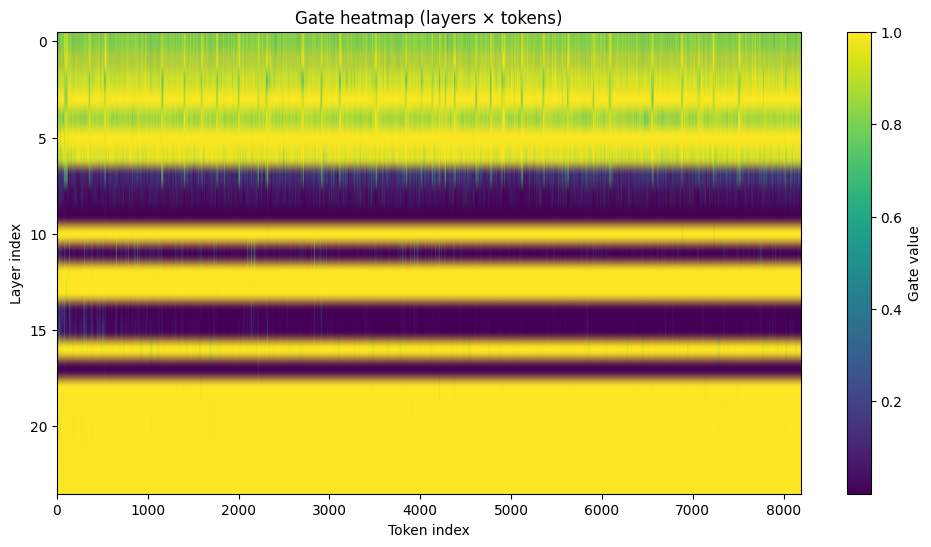

In [52]:
# decisions on training data
visualize_gate_heatmap(gate_store[:24])

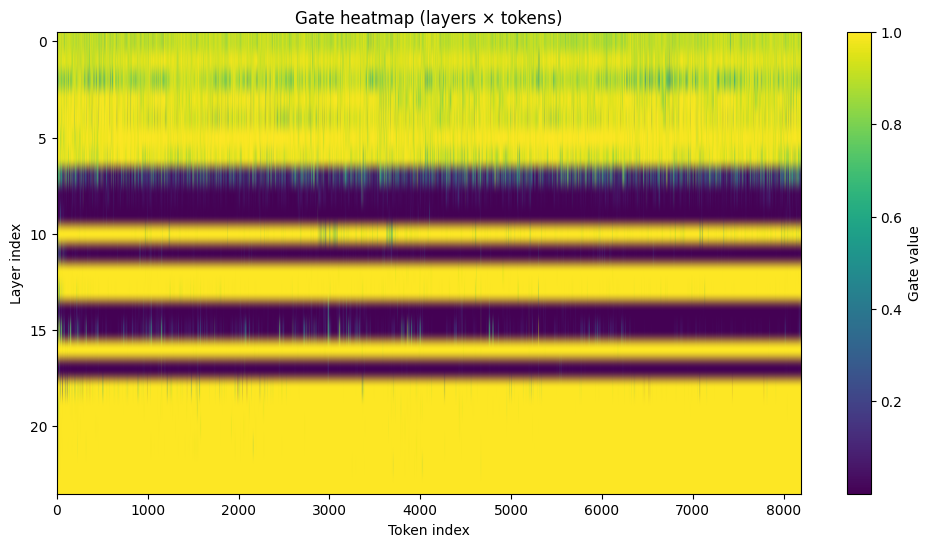

In [53]:
# decisions on validation data
visualize_gate_heatmap(gate_store[-24:])

## Gated Model Evaluation

In [54]:
gate_store.clear()
model.eval()
eval_ppl(model, wiki_testloader, device=DEV)

37.74723815917969

In [55]:
# skip ratio
torch.Tensor([x.mean() for x in gate_store]).mean()

tensor(0.6976)

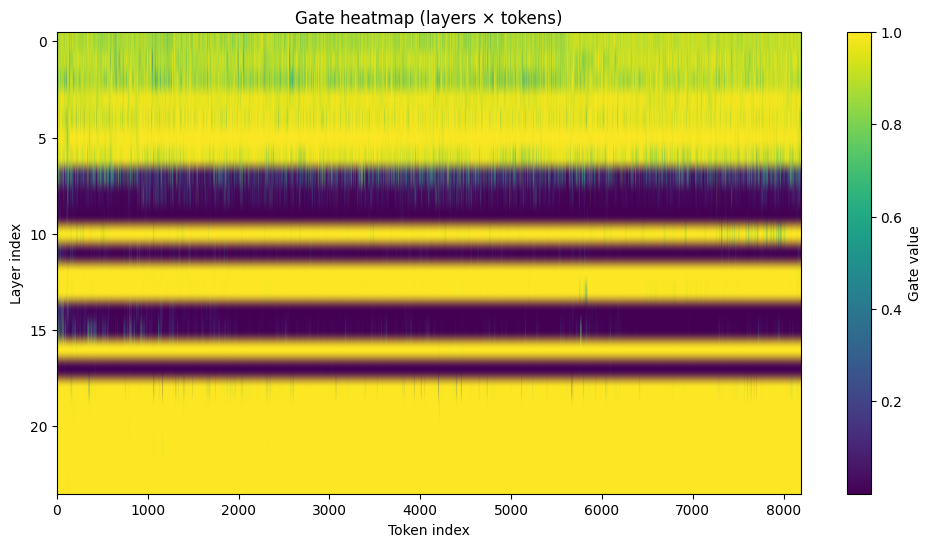

In [56]:
# decisions on wiki test data
visualize_gate_heatmap(gate_store[-24:])

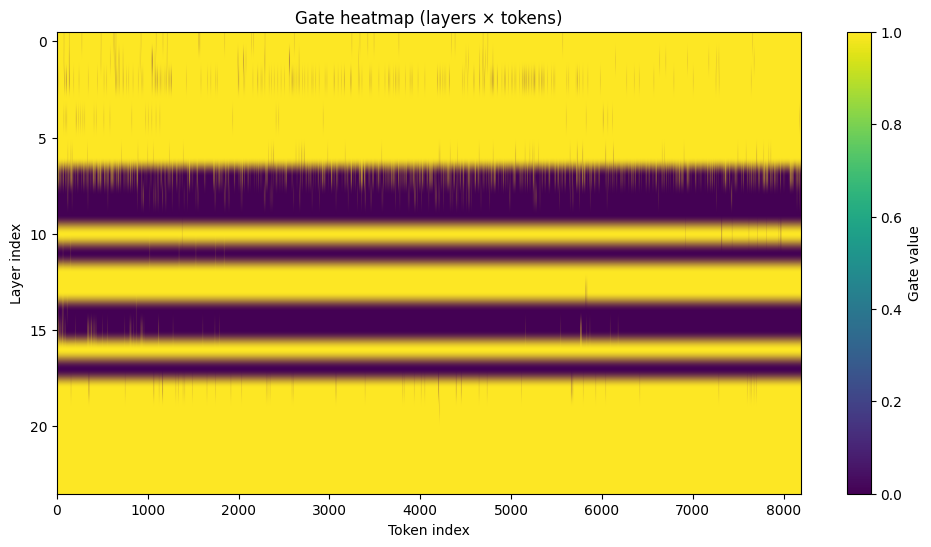

In [61]:
# binary decisions on wiki test data
visualize_gate_heatmap([x.round() for x in gate_store[-24:]])

Text(0.5, 1.0, 'Distribution of decisions')

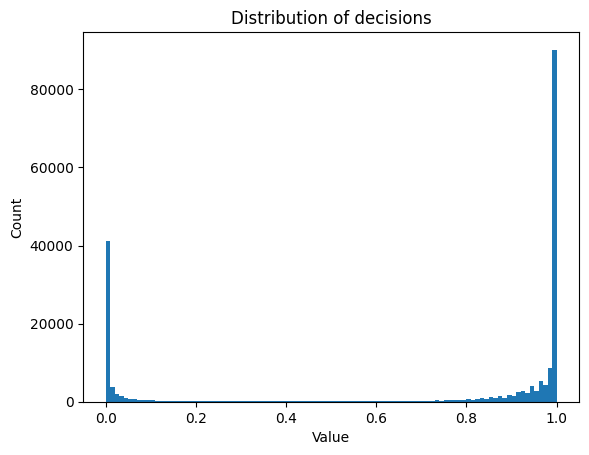

In [57]:
flat = torch.cat([t.reshape(-1) for t in gate_store[-24:]])
values = flat.float().detach().cpu().numpy()
plt.hist(values, bins=100)
plt.xlabel("Value")
plt.ylabel("Count")
plt.title('Distribution of decisions')

## Average weights and bias

<BarContainer object of 24 artists>

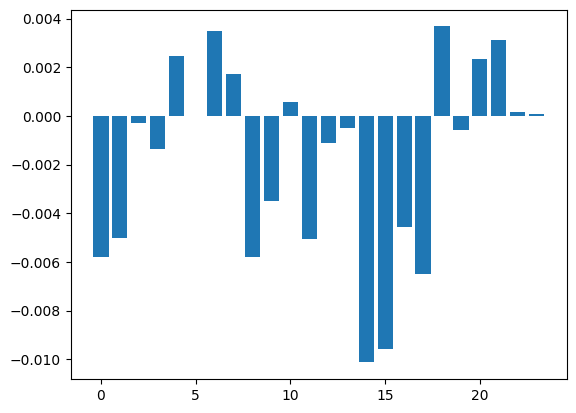

In [58]:
plt.bar(range(24), [model.model.layers[i].mlp.gate.proj.weight.mean().item() for i in range(24)])

<BarContainer object of 24 artists>

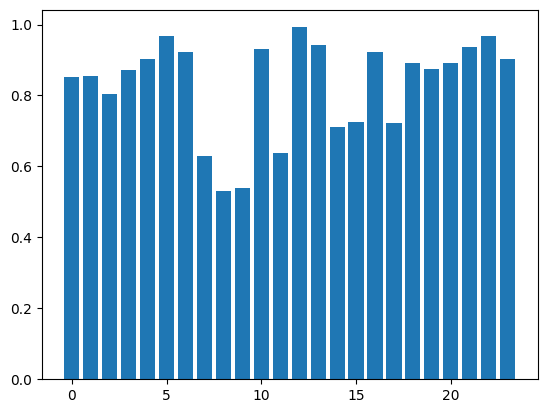

In [59]:
plt.bar(range(24), [model.model.layers[i].mlp.gate.proj.bias.item() for i in range(24)])